# JetGuard - Robust Validation and Sensor Insights

This notebook strengthens the model comparison with five-fold GroupKFold validation across FD001 training engines, then explores sensor/RUL relationships. All folds keep each engine intact; fold scalers are fitted only on fold-training engines. The official test set is not used here.

The sensor trends and RUL bands are exploratory associations, not causal findings or maintenance thresholds.

In [1]:
from pathlib import Path
import gc
import json
import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DATASET_DIR = PROJECT_ROOT / "dataset"
REPORT_DIR = PROJECT_ROOT / "reports"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_SPLITS = 5
WINDOW_LENGTH = 50
HIDDEN_SIZE = 64
BATCH_SIZE = 256
MAX_EPOCHS = 80
PATIENCE = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
print("Device:", DEVICE)

Device: cpu


In [2]:
with (PROCESSED_DIR / "feature_metadata.json").open("r", encoding="utf-8") as file:
    feature_metadata = json.load(file)
train_df = pd.read_csv(PROCESSED_DIR / "train_FD001_processed.csv")
sensor_columns = feature_metadata["informative_sensors"]
sequence_features = ["setting_1", "setting_2", "setting_3"] + sensor_columns

assert train_df.engine_id.nunique() == 100
assert not train_df.duplicated(["engine_id", "cycle"]).any()
print("Training engines:", train_df.engine_id.nunique())
print("Sequence input channels:", len(sequence_features))

Training engines: 100
Sequence input channels: 18


In [3]:
ROLLING_WINDOWS = [5, 10, 30]
LAG_STEPS = [1, 5, 10]


def make_tabular_features(frame):
    ordered = frame.sort_values(["engine_id", "cycle"]).copy()
    generated = {}
    for window in ROLLING_WINDOWS:
        for sensor in sensor_columns:
            grouped = ordered.groupby("engine_id", sort=False)[sensor]
            generated[f"{sensor}_roll_mean_{window}"] = grouped.transform(
                lambda values, size=window: values.rolling(size, min_periods=1).mean()
            )
            generated[f"{sensor}_roll_std_{window}"] = grouped.transform(
                lambda values, size=window: values.rolling(size, min_periods=2).std()
            ).fillna(0.0)
    for lag in LAG_STEPS:
        for sensor in sensor_columns:
            shifted = ordered.groupby("engine_id", sort=False)[sensor].shift(lag)
            generated[f"{sensor}_lag_{lag}"] = shifted.fillna(ordered[sensor])
    features = pd.DataFrame(generated, index=ordered.index)
    result = pd.concat([ordered, features], axis=1)
    feature_names = ["setting_1", "setting_2", "setting_3"] + list(generated) + sensor_columns
    # Match the 30-cycle feature warm-up used by the tabular baseline.
    return result.loc[result.cycle >= 30].reset_index(drop=True), feature_names


tabular_df, tabular_feature_names = make_tabular_features(train_df)
print("Tabular rows:", len(tabular_df), "features:", len(tabular_feature_names))

Tabular rows: 17731 features: 153


In [4]:
def nasa_score(y_true, y_pred):
    error = np.asarray(y_pred) - np.asarray(y_true)
    penalty = np.where(error < 0, np.exp(-error / 13.0) - 1.0, np.exp(error / 10.0) - 1.0)
    return float(penalty.sum())


def metrics(y_true, raw_prediction):
    y_true = np.asarray(y_true, dtype=float)
    prediction = np.clip(np.asarray(raw_prediction, dtype=float), 0.0, 125.0)
    nonzero = np.abs(y_true) > 1e-8
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, prediction))),
        "MAE": float(mean_absolute_error(y_true, prediction)),
        "MAPE": float(mean_absolute_percentage_error(y_true[nonzero], prediction[nonzero])),
        "NASA_score": nasa_score(y_true, prediction),
    }


folds = []
cv = GroupKFold(n_splits=N_SPLITS)
for train_indices, validation_indices in cv.split(train_df, groups=train_df.engine_id):
    train_engines = set(train_df.iloc[train_indices].engine_id.unique())
    validation_engines = set(train_df.iloc[validation_indices].engine_id.unique())
    assert train_engines.isdisjoint(validation_engines)
    folds.append((train_engines, validation_engines))
print("Prepared", len(folds), "engine-disjoint folds")

Prepared 5 engine-disjoint folds


In [5]:
tabular_fold_results = []
for fold_number, (train_engines, validation_engines) in enumerate(folds, start=1):
    train_fold = tabular_df[
        tabular_df.engine_id.isin(train_engines) & (tabular_df.cycle >= WINDOW_LENGTH)
    ]
    validation_fold = tabular_df[
        tabular_df.engine_id.isin(validation_engines) & (tabular_df.cycle >= WINDOW_LENGTH)
    ]
    scaler = StandardScaler()
    x_train = scaler.fit_transform(train_fold[tabular_feature_names])
    x_validation = scaler.transform(validation_fold[tabular_feature_names])
    y_train = train_fold.RUL_capped.to_numpy()
    y_validation = validation_fold.RUL_capped.to_numpy()

    for model_name, model in [
        ("Ridge", Ridge(alpha=1.0)),
        ("Random Forest", RandomForestRegressor(
            n_estimators=200, max_depth=20, min_samples_leaf=2,
            random_state=SEED, n_jobs=-1,
        )),
    ]:
        started = time.perf_counter()
        model.fit(x_train, y_train)
        predictions = model.predict(x_validation)
        elapsed = time.perf_counter() - started
        tabular_fold_results.append({
            "fold": fold_number,
            "model": model_name,
            "validation_engines": len(validation_engines),
            "validation_rows": len(validation_fold),
            "training_seconds": elapsed,
            **metrics(y_validation, predictions),
        })
    print(f"Completed tabular fold {fold_number}/{N_SPLITS}")


tabular_fold_metrics = pd.DataFrame(tabular_fold_results)
tabular_fold_metrics.to_csv(REPORT_DIR / "group_cv_tabular_fold_metrics.csv", index=False)
tabular_fold_metrics

Completed tabular fold 1/5


Completed tabular fold 2/5


Completed tabular fold 3/5


Completed tabular fold 4/5


Completed tabular fold 5/5


,fold,model,validation_engines,validation_rows,training_seconds,RMSE,MAE,MAPE,NASA_score
0,1,Ridge,20,3140,0.022328,18.271589,14.895558,0.329481,15040.313530
1,1,Random Forest,20,3140,22.463582,18.676138,13.984359,0.225613,20604.939722
2,2,Ridge,20,3153,0.024554,16.892291,13.704088,0.314573,14161.161581
3,2,Random Forest,20,3153,25.165972,18.272003,13.811244,0.225670,20321.894581
4,3,Ridge,20,3146,0.022952,16.620191,13.303833,0.296067,14248.287769
5,3,Random Forest,20,3146,23.105850,18.252436,13.276574,0.255515,30619.928623
6,4,Ridge,20,3145,0.023899,15.700557,12.246645,0.270396,12235.301272
7,4,Random Forest,20,3145,27.162766,17.622256,13.272674,0.233710,24912.651358
8,5,Ridge,20,3147,0.023908,18.326913,14.421329,0.323233,20970.721599
9,5,Random Forest,20,3147,24.484946,17.124598,12.063492,0.209204,21122.084356


In [6]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_sequences(frame, target=True):
    sequences, targets = [], []
    for _, engine in frame.groupby("engine_id", sort=True):
        engine = engine.sort_values("cycle")
        values = engine[sequence_features].to_numpy(dtype=np.float32)
        rul = engine.RUL_capped.to_numpy(dtype=np.float32) if target else None
        for end in range(WINDOW_LENGTH - 1, len(engine)):
            start = end - WINDOW_LENGTH + 1
            sequences.append(values[start:end + 1])
            if target:
                targets.append(rul[end])
    x = np.stack(sequences)
    if target:
        return x, np.asarray(targets, dtype=np.float32)
    return x


class CrossValidatedLSTM(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.recurrent = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.regression = nn.Linear(hidden_size, 1)

    def forward(self, sequence):
        outputs, _ = self.recurrent(sequence)
        return self.regression(outputs[:, -1]).squeeze(1)


def fit_lstm_fold(x_train, y_train, x_validation, y_validation, seed):
    seed_everything(seed)
    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train)),
        batch_size=BATCH_SIZE, shuffle=True,
    )
    validation_loader = DataLoader(
        TensorDataset(torch.from_numpy(x_validation), torch.from_numpy(y_validation)),
        batch_size=BATCH_SIZE, shuffle=False,
    )
    model = CrossValidatedLSTM(len(sequence_features), HIDDEN_SIZE).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_function = nn.MSELoss()
    best_state, best_loss, best_epoch, patience = None, float("inf"), 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad()
            loss_function(model(batch_x), batch_y).backward()
            optimizer.step()
        model.eval()
        validation_losses = []
        with torch.no_grad():
            for batch_x, batch_y in validation_loader:
                batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
                validation_losses.append(loss_function(model(batch_x), batch_y).item())
        current_loss = float(np.mean(validation_losses))
        if current_loss < best_loss:
            best_loss, best_epoch = current_loss, epoch
            best_state, patience = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            patience += 1
            if patience >= PATIENCE:
                break
    if best_state is None:
        raise RuntimeError("LSTM fold training did not produce a checkpoint.")
    model.load_state_dict(best_state)
    model.eval()
    predictions = []
    with torch.no_grad():
        for batch_x, _ in validation_loader:
            predictions.extend(model(batch_x.to(DEVICE)).cpu().numpy())
    return model, np.asarray(predictions), best_epoch, best_loss

In [7]:
lstm_fold_results = []
lstm_fold_models = {}
for fold_number, (train_engines, validation_engines) in enumerate(folds, start=1):
    raw_train_fold = train_df[train_df.engine_id.isin(train_engines)].copy()
    raw_validation_fold = train_df[train_df.engine_id.isin(validation_engines)].copy()
    fold_scaler = StandardScaler().fit(raw_train_fold[sequence_features])
    for frame in (raw_train_fold, raw_validation_fold):
        scaled_values = fold_scaler.transform(frame[sequence_features])
        for column_index, column in enumerate(sequence_features):
            frame[column] = scaled_values[:, column_index]

    x_train, y_train = make_sequences(raw_train_fold)
    x_validation, y_validation = make_sequences(raw_validation_fold)
    started = time.perf_counter()
    model, predictions, best_epoch, best_loss = fit_lstm_fold(
        x_train, y_train, x_validation, y_validation, SEED + fold_number
    )
    elapsed = time.perf_counter() - started
    lstm_fold_models[fold_number] = model
    lstm_fold_results.append({
        "fold": fold_number,
        "model": "LSTM (50-cycle)",
        "validation_engines": len(validation_engines),
        "validation_rows": len(y_validation),
        "best_epoch": best_epoch,
        "best_validation_mse": best_loss,
        "training_seconds": elapsed,
        **metrics(y_validation, predictions),
    })
    print(f"Completed LSTM fold {fold_number}/{N_SPLITS}; best epoch={best_epoch}")
    del x_train, y_train, x_validation, y_validation, raw_train_fold, raw_validation_fold
    gc.collect()

lstm_fold_metrics = pd.DataFrame(lstm_fold_results)
lstm_fold_metrics.to_csv(REPORT_DIR / "group_cv_lstm_fold_metrics.csv", index=False)
lstm_fold_metrics

Completed LSTM fold 1/5; best epoch=63


Completed LSTM fold 2/5; best epoch=64


Completed LSTM fold 3/5; best epoch=66


Completed LSTM fold 4/5; best epoch=78


Completed LSTM fold 5/5; best epoch=67


,fold,model,validation_engines,validation_rows,best_epoch,best_validation_mse,training_seconds,RMSE,MAE,MAPE,NASA_score
0,1,LSTM (50-cycle),20,3140,63,192.949791,90.806357,14.191113,10.989407,0.175879,10485.334981
1,2,LSTM (50-cycle),20,3153,64,197.684195,85.421334,14.079326,10.364351,0.162183,8998.061914
2,3,LSTM (50-cycle),20,3146,66,144.563332,96.695115,12.084402,9.439777,0.171711,6981.990414
3,4,LSTM (50-cycle),20,3145,78,153.643704,108.804184,12.666172,9.185202,0.153061,9865.704305
4,5,LSTM (50-cycle),20,3147,67,199.554322,92.517692,14.292313,11.036070,0.187617,12084.798248


In [8]:
all_fold_metrics = pd.concat(
    [tabular_fold_metrics, lstm_fold_metrics], ignore_index=True, sort=False
)
summary_rows = []
for model_name, group in all_fold_metrics.groupby("model"):
    row = {"model": model_name}
    for metric in ["RMSE", "MAE", "MAPE", "NASA_score"]:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_std"] = group[metric].std(ddof=1)
    row["training_seconds_mean"] = group.training_seconds.mean()
    summary_rows.append(row)
cv_summary = pd.DataFrame(summary_rows).sort_values("NASA_score_mean")
cv_summary.to_csv(REPORT_DIR / "group_cv_summary.csv", index=False)
cv_summary

,model,RMSE_mean,RMSE_std,MAE_mean,MAE_std,MAPE_mean,MAPE_std,NASA_score_mean,NASA_score_std,training_seconds_mean
0,LSTM (50-cycle),13.462665,1.016518,10.202961,0.859782,0.170090,0.013190,9683.177972,1884.830889,94.848936
2,Ridge,17.162308,1.128088,13.714291,1.026871,0.306750,0.023902,15331.157150,3317.193713,0.023528
1,Random Forest,17.989486,0.613054,13.281669,0.751380,0.229943,0.016846,23516.299728,4382.460779,24.476623


In [9]:
correlation_rows = []
for engine_id, engine in train_df.groupby("engine_id", sort=True):
    for sensor in sensor_columns:
        if engine[sensor].nunique() > 1:
            rho = spearmanr(engine[sensor], engine.RUL).statistic
            correlation_rows.append({"engine_id": engine_id, "sensor": sensor, "spearman_rho": rho})
correlations = pd.DataFrame(correlation_rows)

sensor_summary = correlations.groupby("sensor").spearman_rho.agg(
    median_rho="median",
    median_absolute_rho=lambda values: values.abs().median(),
    engines_observed="count",
).reset_index()
sensor_summary["negative_rho_fraction"] = correlations.groupby("sensor").spearman_rho.apply(
    lambda values: (values < 0).mean()
).reindex(sensor_summary.sensor).to_numpy()
sensor_summary["positive_rho_fraction"] = correlations.groupby("sensor").spearman_rho.apply(
    lambda values: (values > 0).mean()
).reindex(sensor_summary.sensor).to_numpy()
sensor_summary = sensor_summary.sort_values("median_absolute_rho", ascending=False)
sensor_summary.to_csv(REPORT_DIR / "sensor_rul_correlation_by_engine.csv", index=False)
sensor_summary

,sensor,median_rho,median_absolute_rho,engines_observed,negative_rho_fraction,positive_rho_fraction
0,sensor_11,-0.819030,0.819030,100,1.000000,0.000000
1,sensor_12,0.807523,0.807523,100,0.000000,1.000000
10,sensor_4,-0.783958,0.783958,100,1.000000,0.000000
12,sensor_7,0.774188,0.774188,100,0.000000,1.000000
13,sensor_8,-0.768409,0.768409,100,1.000000,0.000000
3,sensor_14,-0.663398,0.767057,100,0.600000,0.400000
2,sensor_13,-0.761977,0.761977,100,1.000000,0.000000
14,sensor_9,-0.739202,0.750621,100,0.710000,0.290000
4,sensor_15,-0.720953,0.720953,100,1.000000,0.000000
8,sensor_21,0.708005,0.708005,100,0.000000,1.000000


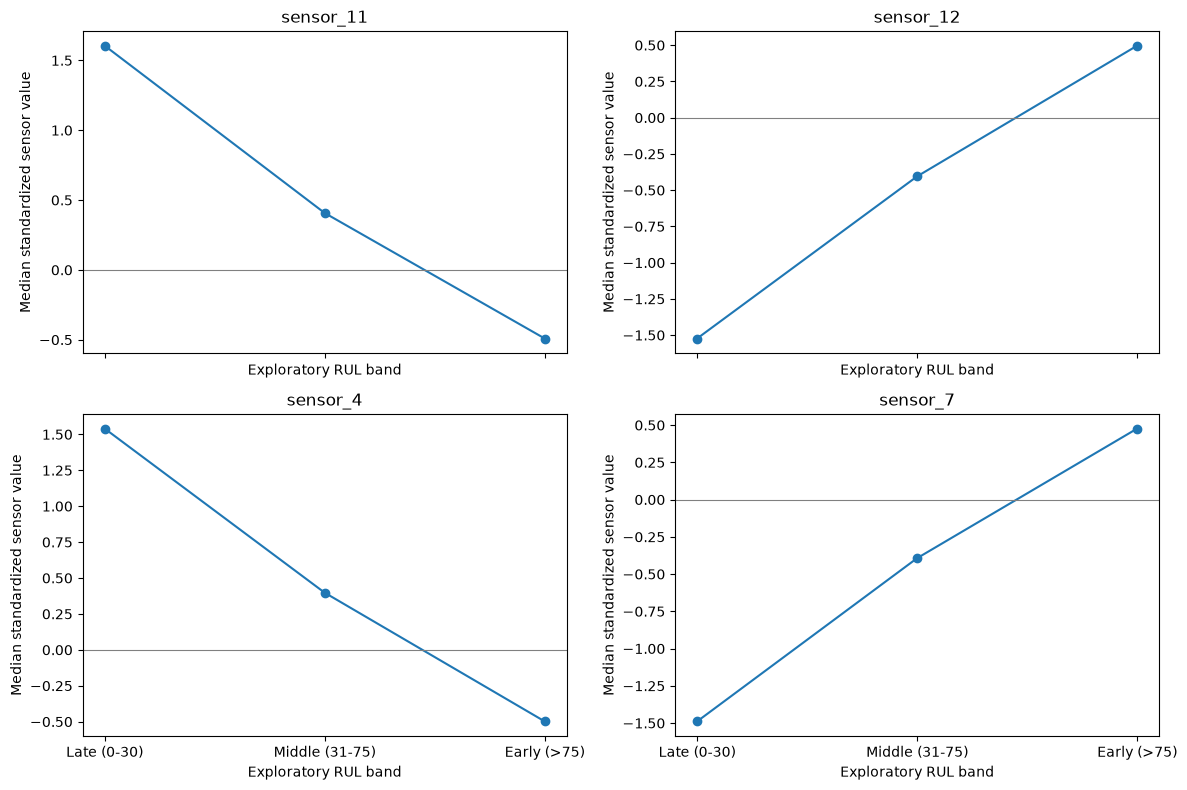

Most consistently associated sensors (ranked by median |within-engine rho|):


,sensor,median_rho,median_absolute_rho,engines_observed,negative_rho_fraction,positive_rho_fraction
0,sensor_11,-0.819030,0.819030,100,1.00,0.00
1,sensor_12,0.807523,0.807523,100,0.00,1.00
10,sensor_4,-0.783958,0.783958,100,1.00,0.00
12,sensor_7,0.774188,0.774188,100,0.00,1.00
13,sensor_8,-0.768409,0.768409,100,1.00,0.00
3,sensor_14,-0.663398,0.767057,100,0.60,0.40
2,sensor_13,-0.761977,0.761977,100,1.00,0.00
14,sensor_9,-0.739202,0.750621,100,0.71,0.29


In [10]:
stage_frame = train_df[["RUL"] + sensor_columns].copy()
stage_frame["life_stage"] = pd.cut(
    stage_frame.RUL,
    bins=[-np.inf, 30, 75, np.inf],
    labels=["Late (0-30)", "Middle (31-75)", "Early (>75)"],
    ordered=True,
)
for sensor in sensor_columns:
    standard_deviation = stage_frame[sensor].std()
    stage_frame[f"{sensor}_z"] = (stage_frame[sensor] - stage_frame[sensor].mean()) / standard_deviation

z_columns = [f"{sensor}_z" for sensor in sensor_columns]
stage_profiles = stage_frame.groupby("life_stage", observed=True)[z_columns].median()
stage_profiles.columns = sensor_columns
stage_profiles.to_csv(REPORT_DIR / "sensor_median_profile_by_life_stage.csv")

ranked_sensors = sensor_summary.sensor.head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for axis, sensor in zip(axes.flat, ranked_sensors):
    axis.plot(stage_profiles.index.astype(str), stage_profiles[sensor], marker="o")
    axis.axhline(0, color="gray", linewidth=0.8)
    axis.set_title(sensor)
    axis.set_ylabel("Median standardized sensor value")
    axis.set_xlabel("Exploratory RUL band")
plt.tight_layout()
plt.savefig(REPORT_DIR / "sensor_trends_by_life_stage.png", dpi=160, bbox_inches="tight")
plt.show()
print("Most consistently associated sensors (ranked by median |within-engine rho|):")
sensor_summary.head(8)

## Limitations and interpretation cautions

- FD001 represents one simulated operating condition and one fault mode; results do not establish performance on FD002-FD004 or real aircraft.
- Sensor measurements include noise, and the dataset does not provide complete physical context for assigning causal explanations to sensor trends.
- The 125-cycle cap and the 0-30 / 31-75 / >75 RUL bands are modeling/analysis choices, not validated maintenance thresholds.
- The current validation uses five engine-grouped folds from the FD001 training partition. This tests variation across engines within FD001, but is not external validation.
- The official test set remains the final benchmark. It was not included in this cross-validation or sensor trend analysis.
- Deployment would require domain review, calibration, uncertainty handling, monitoring, and safety procedures before operational use.

### Recommended follow-up

1. Review fold mean and standard deviation for each metric; avoid selecting a model from a single split or one metric alone.
2. Investigate sensor directions and consistency across engines with domain guidance; treat correlations as associations.
3. Evaluate generalization on FD002-FD004 and assess uncertainty before any real-world claims.
4. Incorporate the supported results, limitations, and team contributions into the final report and presentation.